# Lab 14-05 · Single-Cycle Datapath and Control

Companion to [chapter 14-05](../../chapters/14-05-single-cycle-datapath.md) and to the Verilog core in this directory. Three parts: a timing explorer; the control table read from the Verilog decoder; and a comparison of the core's register writes with the course's Python simulator. Part 3 runs the core if Icarus Verilog is installed. Run the cells in order.

In [1]:
import re, shutil, subprocess, sys, tempfile
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../verify').resolve()))
from _rv32 import Sim

## Part 1 · Which instruction sets the clock?

The function below follows each class's longest path (§3.4). Change the delays and see which class becomes critical.

**Predict first:** if the data memory were as fast as the register file (100 ps), which class would set the clock?

§3.4 delays                load 730, R-type 530, store 505, branch 465, JAL 415 -> T = 730 ps (load), f = 1.370 GHz
data memory 120 ps         load 650, R-type 530, store 505, branch 465, JAL 415 -> T = 650 ps (load), f = 1.538 GHz
data memory 100 ps         load 630, R-type 530, store 505, branch 465, JAL 415 -> T = 630 ps (load), f = 1.587 GHz
instruction memory 300 ps  load 830, R-type 630, store 605, branch 565, JAL 515 -> T = 830 ps (load), f = 1.205 GHz


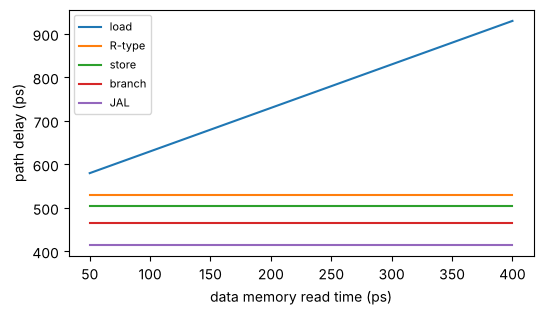

In [2]:
def paths(d):
    front = d['clkq'] + d['imem'] + max(d['rf'], d['imm'])
    return {'load':   front + d['mux'] + d['alu'] + d['dmem'] + d['mux'] + d['rf_su'],
            'R-type': front + d['mux'] + d['alu'] + d['mux'] + d['rf_su'],
            'store':  front + d['mux'] + d['alu'] + d['dmem_su'],
            'branch': max(d['clkq'] + d['imem'] + d['rf'] + d['cmp'], d['clkq'] + d['imem'] + d['imm'] + d['add']) + d['mux'] + d['su'],
            'JAL':    d['clkq'] + d['imem'] + d['imm'] + d['add'] + d['mux'] + d['su']}
base = dict(clkq=40, su=20, imem=200, rf=100, rf_su=20, imm=50, mux=25, alu=120, add=80, cmp=80, dmem=200, dmem_su=20)
for label, change in (('§3.4 delays', {}), ('data memory 120 ps', {'dmem': 120}), ('data memory 100 ps', {'dmem': 100}),
                      ('instruction memory 300 ps', {'imem': 300})):
    p = paths({**base, **change}); crit = max(p, key=p.get)
    print(f'{label:26s}', ', '.join(f'{k} {v}' for k, v in p.items()), f'-> T = {p[crit]} ps ({crit}), f = {1e3 / p[crit]:.3f} GHz')
dm = range(50, 401, 10)
plt.figure(figsize=(6, 3.2))
for k in ('load', 'R-type', 'store', 'branch', 'JAL'):
    plt.plot(dm, [paths({**base, 'dmem': x})[k] for x in dm], label=k)
plt.xlabel('data memory read time (ps)'); plt.ylabel('path delay (ps)'); plt.legend(fontsize=8); plt.show()

## Part 2 · The control table, read from the Verilog

Parse the main decoder's `case` statement and print the signals for each opcode. Compare with §3.3's table.

In [3]:
dec = Path('rv32_decoder.v').read_text()
names = ['reg_write', 'a_sel', 'b_sel', 'imm_sel', 'mem_write', 'result_src', 'branch', 'jump', 'jalr', 'halt', 'alu_op']
print(f'{"opcode":9s} {"class":11s}', ' '.join(f'{n:>10s}' for n in names))
for m in re.finditer(r"7'b([01]{7}): begin (.*?)end\s*//\s*(.*)", dec):
    sig = {n: int(v, 2 if b == 'b' else 10) for n, b, v in re.findall(r"(\w+) = \d+'([bd])(\d+)", m.group(2))}
    print(f'{m.group(1):9s} {m.group(3).strip():11s}', ' '.join(f'{sig.get(n, 0):>10d}' for n in names))

opcode    class        reg_write      a_sel      b_sel    imm_sel  mem_write result_src     branch       jump       jalr       halt     alu_op
0110011   R-type               1          0          0          0          0          0          0          0          0          0          2
0010011   I-type ALU           1          0          1          0          0          0          0          0          0          0          2
0000011   LW                   1          0          1          0          0          1          0          0          0          0          0
0100011   SW                   0          0          1          1          1          0          0          0          0          0          0
1100011   branches             0          0          0          2          0          0          1          0          0          0          1
1101111   JAL                  1          0          0          4          0          2          0          1          0          0          0

## Part 3 · The Verilog core against the Python simulator

Build the test program's memory image from `program.hex` and `data.hex`, run it on the Python simulator, and, if Icarus Verilog is available, run the testbench with `+trace` and compare every register write.

In [4]:
words = [int(x, 16) for x in Path('program.hex').read_text().split()]
data = [int(x, 16) for x in Path('data.hex').read_text().split()]
mem = {4 * i + k: (w >> 8 * k) & 0xFF for i, w in enumerate(words) for k in range(4)}
mem.update({4 * i + k: (w >> 8 * k) & 0xFF for i, w in enumerate(data) if w for k in range(4)})
sim, wtrace = Sim(mem, 0), []
n = sim.run(wtrace=wtrace)
rd = lambda a: int.from_bytes(bytes(sim.mem.get(a + k, 0) for k in range(4)), 'little')
print(f'Python simulator: {n} instructions, {len(wtrace)} register writes, sum = {rd(0x100)}, fib(10) = {rd(0x104)}')
if shutil.which('iverilog') and shutil.which('vvp'):
    with tempfile.TemporaryDirectory() as td:
        for f in Path('.').glob('*'):
            if f.suffix in ('.v', '.hex', '.vh'): shutil.copy(f, td)
        srcs = ['rv32_single_tb.v', 'rv32_single.v', 'rv32_decoder.v', 'rv32_immgen.v', 'rv32_alu.v', 'rv32_regfile.v']
        subprocess.run(['iverilog', '-g2012', '-o', 'sim.vvp', *srcs], cwd=td, check=True)
        out = subprocess.run(['vvp', '-n', 'sim.vvp', '+trace'], cwd=td, capture_output=True, text=True).stdout
        print(out.strip())
        vtrace = [(int(a, 16), int(r), int(x, 16)) for a, r, x in (ln.split() for ln in (Path(td) / 'trace.txt').read_text().splitlines())]
    mism = [i for i, (a, b) in enumerate(zip(vtrace, wtrace)) if a != b]
    print(f'Verilog wrote {len(vtrace)} registers; mismatches with the Python simulator: {len(mism) + abs(len(vtrace) - len(wtrace))}')
else:
    print('Icarus Verilog not found: install it (see the lab handout) to run the core.')

Python simulator: 1923 instructions, 1281 register writes, sum = 115, fib(10) = 55
sum = 115, fib(10) = 55, 1923 cycles (CPI = 1), 1281 register writes, 1.404 us at 730 ps
TEST PASSED
rv32_single_tb.v:65: $finish called at 1404885 (1ps)
Verilog wrote 1281 registers; mismatches with the Python simulator: 0


**Explore.** Break the core on purpose: in `rv32_decoder.v`, make the ALU decoder ignore the opcode when choosing SUB (so `addi` with bit 30 set subtracts). Re-run Part 3. Which register write is the first to differ, and which instruction caused it?